## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Heidi Williams

**Date:** 10/21/2026

In [1]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/ML/A05-pca
!ls

Mounted at /content/drive
/content/drive/MyDrive/ML/A05-pca
data  notebook.ipynb  README.md


In [2]:
#Q1
#code to run
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

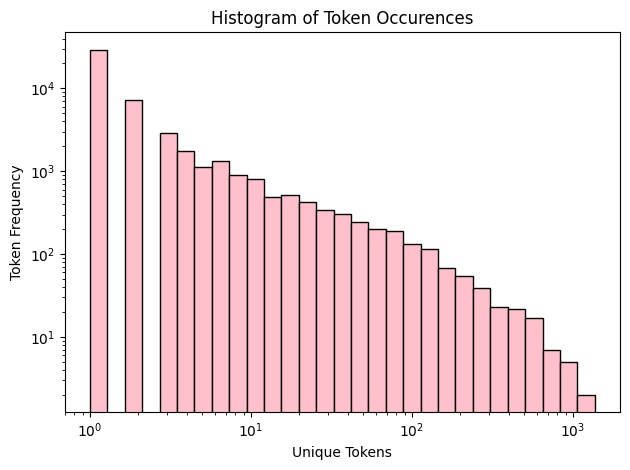

In [3]:
import matplotlib.pyplot as plt
import numpy as np

counts = list(token_count.values())
bins = np.logspace(0, np.log10(max(counts) + 1), 30)

plt.hist(counts, bins=bins, color="pink", edgecolor="black")

plt.xscale("log")
plt.yscale("log")
#used for scaling
plt.xlabel("Unique Tokens")
plt.ylabel("Token Frequency")
plt.title("Histogram of Token Occurences")
plt.tight_layout()
plt.show()

The histogram is skewed right, which means that most of the tokens have a lower frequency on the log scale (many only one and most under 100). The few that are over 100 occurances further add to the right skew by creating a tail.

In [4]:
#Q2
#1
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.drop(columns="Email Type")
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
#Q2
#2
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X_train, y_train)

print(model.score(X_test, y_test))
print(model.score(X_train, y_train))

0.6658718438847919
0.7670143724934355


The test R squared was 0.6658718438847919 and the training R squared was  0.7670143724934355.

In [6]:
#Q2
#3
coefficients = pd.Series(model.coef_, index=X.columns)
print(coefficients.sort_values(key=abs, ascending=False).head(20))

intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
shopper             -0.486678
april's             -0.486483
arial,              -0.482141
laser                0.473607
issue:              -0.465547
dtype: float64


Intervention had the largest coefficient by absolute value; it very strongly pushes towards a legitamate email. Localized had the largest positive value, pushing an email greatly towards being a phishing email.

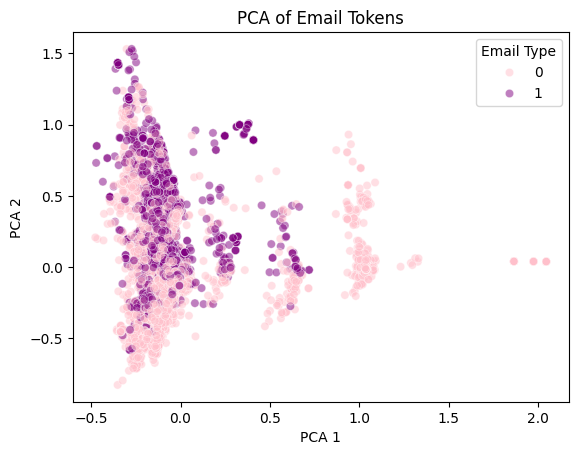

In [7]:
#Q3
from sklearn.decomposition import PCA
import seaborn as sns

components = PCA(n_components=2).fit_transform(X)

sns.scatterplot(x=components[:, 0], y=components[:, 1], hue=y, palette={0: "pink", 1: "purple"}, alpha=0.5)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("PCA of Email Tokens")
plt.show()

This plot shows a lot of overlap between -0.5 and 0.5 on PCA 1, so there is not a clear separation between phishing and legitimate emails in that specific range. The points almost look like they form vertical bands, which could mean some emails use similar words. Farther to the right, especially around 1, the emails are mostly legitimate, but there are still phishing emails near 0.5

In [8]:
#Q4
pca = PCA(n_components=2610)
train_pca = pca.fit_transform(X_train)
test_pca = pca.transform(X_test)

pca_model = LinearRegression().fit(train_pca, y_train)

print(pca_model.score(train_pca, y_train))
print( pca_model.score(test_pca, y_test))

0.7662326827745849
0.6683390643101164


The PCA training R squared is 0.7662326827745849 and the PCA test R squared is 0.6683390643101164.

This performance is similar to the linear regression, as they only begin to differ in the thousandths place. The PCA training R squared was slightly lower by about 0.0008 while the test R squared was slightly higher by about 0.0024.This concludes that PCA did perform better, but by a slim margin.

Q5

The advantage of using PCA is that it combines information from the tokens into fewer variables that are not correlated with each other. In our results,we decreased the number by 101 variables in the PCA analysis and still had very similar R squared values. The test performance was even slightly higher, showing that we could remove some information without hurting predictions; the clear advantage of PCA.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 2f59f446f47eef52460341cc7fabc2d60ebd9ec6
- **AI tool and model used:** GPT Astra-6

### *Prompts used

1. look through this notebook and find mistakes that would cost me rubric points

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q1: Your histogram’s axis labels are incorrect.
The histogram code correctly plots token occurrence counts, but the horizontal axis represents how often a token occurs, and the vertical axis represents how many unique tokens fall in that bin. Change the labels to:
plt.xlabel("Occurrences per Token")
plt.ylabel("Number of Unique Tokens")
plt.title("Histogram of Token Occurrences")
2. Q4: Make the performance comparison more precise.
Your results are:
Model	Training R²	Test R²
Original linear regression	0.767014	0.665872
PCA regression	0.766233	0.668339
Training R² decreased by 0.000782, and test R² increased by 0.002467. Your stated training difference of approximately 0.0008 is correct; the test difference rounds to 0.0025, rather than 0.0024. This is a minor rounding issue.
More importantly, qualify “PCA did perform better” as slightly better on this test split. Training performance was slightly worse, and one split does not establish that PCA will always predict better.
3. Q5: Your explanation is mostly correct, but strengthen the reason PCA helps.
You correctly explain that PCA produces fewer, uncorrelated variables. Add that this reduces redundancy and can reduce multicollinearity and overfitting by discarding low-variance directions. Those directions are not guaranteed to be irrelevant, so frame the nearly unchanged performance as your observed result. Also, PCA forms 2,610 combinations of the original 2,711 features; it does not simply remove 101 individual token columns.
4. Possible execution-order issue: the first data-loading cell comes before your Drive setup.
The original starter cell opens data/all_tokens.pickle before the later cell mounts Drive and changes folders. In a fresh Colab session, running the notebook from the top could fail there. Verify that a fresh “Run all” can find the data from the beginning if reproducibility is graded.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | This seems to be a genuine mistake in labeling on my part; I decided that this change was reasonable.|
| 2 | Accept | I accepted the rounding issue; simple math error on my part. I ignore the part about changing to "PCA did perform better", as I believe marginally better is still better and this clarification was not needed. |
| 3 | Accept  | I changed the language a bit to make it more clear that I understand what PCA does. I verified using my knowledge and the in-class slides. |
| 4 | Reject | This is referring to the code in the instructions, which I retyped later. |


### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [9]:
from google.colab import drive
drive.mount('/content/drive')

%cd /content/drive/MyDrive/ML/A05-pca
!ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/ML/A05-pca
data  notebook.ipynb  README.md


In [10]:
#Q1
#code to run
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

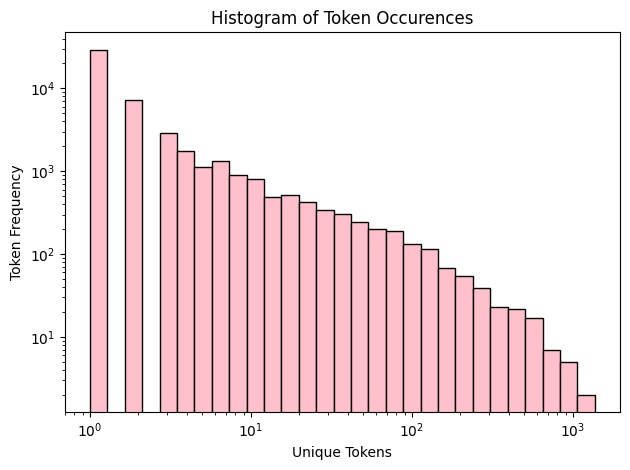

In [11]:
import matplotlib.pyplot as plt
import numpy as np

counts = list(token_count.values())
bins = np.logspace(0, np.log10(max(counts) + 1), 30)

plt.hist(counts, bins=bins, color="pink", edgecolor="black")

plt.xscale("log")
plt.yscale("log")
#used for scaling
plt.xlabel("Unique Tokens")
plt.ylabel("Token Frequency")
plt.title("Histogram of Token Occurences")
plt.tight_layout()
plt.show()

The histogram is skewed right, which means that most of the tokens have a lower frequency on the log scale (many only one and most under 100). The few that are over 100 occurances further add to the right skew by creating a tail.

In [12]:
#Q2
#1
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.drop(columns="Email Type")
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
#Q2
#2
from sklearn.linear_model import LinearRegression
model = LinearRegression().fit(X_train, y_train)

print(model.score(X_test, y_test))
print(model.score(X_train, y_train))

0.6658718438847919
0.7670143724934355


The test R squared was 0.6658718438847919 and the training R squared was 0.7670143724934355.

In [14]:
#Q2
#3
coefficients = pd.Series(model.coef_, index=X.columns)
print(coefficients.sort_values(key=abs, ascending=False).head(20))

intervention        -1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:   -0.622909
helvetica,           0.598560
aging                0.594956
form.                0.576886
gray;               -0.574480
a:active             0.574480
retrieving          -0.573761
zdnet               -0.560954
{text-decoration:    0.497075
xanaax               0.491981
transcript           0.488978
shopper             -0.486678
april's             -0.486483
arial,              -0.482141
laser                0.473607
issue:              -0.465547
dtype: float64


Intervention had the largest coefficient by absolute value; it very strongly pushes towards a legitamate email. Localized had the largest positive value, pushing an email greatly towards being a phishing email.

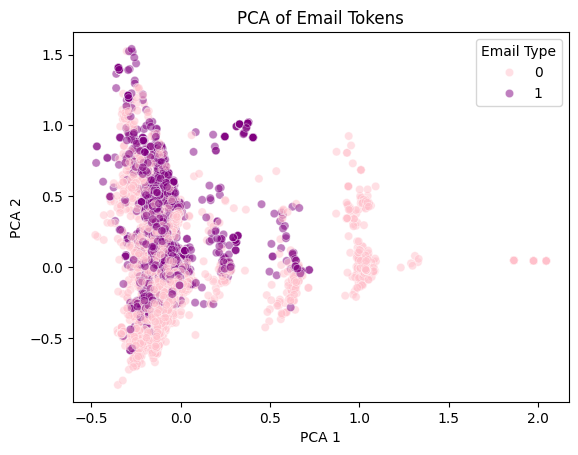

In [15]:
#Q3
from sklearn.decomposition import PCA
import seaborn as sns

components = PCA(n_components=2).fit_transform(X)

sns.scatterplot(x=components[:, 0], y=components[:, 1], hue=y, palette={0: "pink", 1: "purple"}, alpha=0.5)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("PCA of Email Tokens")
plt.show()

This plot shows a lot of overlap between -0.5 and 0.5 on PCA 1, so there is not a clear separation between phishing and legitimate emails in that specific range. The points almost look like they form vertical bands, which could mean some emails use similar words. Farther to the right, especially around 1, the emails are mostly legitimate, but there are still phishing emails near 0.5

In [16]:
#Q4
pca = PCA(n_components=2610)
train_pca = pca.fit_transform(X_train)
test_pca = pca.transform(X_test)

pca_model = LinearRegression().fit(train_pca, y_train)

print(pca_model.score(train_pca, y_train))
print( pca_model.score(test_pca, y_test))

0.7662326827745849
0.6683390643101164


The PCA training R squared is 0.7662326827745849 and the PCA test R squared is 0.6683390643101164.

This performance is similar to the linear regression, as they only begin to differ in the thousandths place. The PCA training R squared was slightly lower by about 0.0008 while the test R squared was slightly higher by about 0.0025.This concludes that PCA did perform better, but by a slim margin.

Q5

The advantage of using PCA is that it combines information from the tokens into fewer variables that are not correlated with each other. In our results,we decreased the number of pieces to work with by 101 in the PCA analysis and still had very similar R squared values. The test performance was even slightly higher, showing that we could remove some information without hurting predictions; the clear advantage of PCA.

### *Reflection on AI assistance
In your own words without generative AI.

AI mainly found a few slight math errors, issues with labeling, and some places that could use further clarification. AI still seemed to be limited in its usual context of not being able to tell objective issues with subjective ones; the model almost seems as if it has an arbitrary number of bullet points it is trying to reach in terms of suggestions and is grasping at things when the majority is correct. I typically ignore most subjective changes, as the assignments are graded on an objective rubric. The final solution was verified by me simply reviewing all the suggestions and deciding which were correct and necessary to implement. When I say necessary, I mean that some seemed more subjective and not an issue that needed to be addressed, just a suggestion that could be addressed. I am concerned that my PCA explanation is not thorough enough, as the AI model did point to that as a possible issue with this particular submission, but I hope that I got my point across properly to get full credit.